In [1]:
import torch
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import graph_utils as gu
%load_ext autoreload
%autoreload 2

## Rho Analysis

In [ ]:
BASE_DIRS = [
    Path("results/afhq_cat/ot"),
    Path("results/celeba/ot"),
]

DATASET_NAMES = [
    "AFHQ Cat",
    "CELEBA",
]

METHODS = [
    "denoising",
    "gaussian_deblurring_FFT",
    "inpainting",
    "paintbrush_inpainting",
    "random_inpainting",
    "superresolution",
]

METRIC_CONFIG = {
    "final_psnr.txt":  ("psnr_rec", "PSNR"),
    "final_ssim.txt":  ("ssim_rec", "SSIM"),
    "final_lpips.txt": ("lpips_rec", "LPIPS"),
}

gu.plot_rho_analysis(
    base_dirs=BASE_DIRS,
    dataset_names=DATASET_NAMES,
    methods=METHODS,
    metric_config=METRIC_CONFIG,
    save_name="all_datasets_metrics_vs_rho_admm.png"
)

## Ablations result table

In [ ]:
ROOT_DIR = Path("results/celeba/ot")
OUT_XLSX = "ablation_summary_celeba.xlsx"

METHODS = [
    "pnp_flow_admm",
    "pnp_flow_fbs",
]

METRIC_FILES = {
    "psnr": "final_psnr.txt",
    "ssim": "final_ssim.txt",
    "lpips": "final_lpips.txt",
}

df = gu.collect_results(METHODS, METRIC_FILES, ROOT_DIR)

if df.empty:
    print("No matching results found.")
else:
    gu.save_outputs(df, OUT_XLSX)
    print(f"Saved Excel: {OUT_XLSX}")
    display(df)

## Result table on images for comparison

In [4]:
# ROOT_DIR = Path("results/celeba/ot")
ROOT_DIR = Path("results_final_simple/celeba/ot")

df = gu.extract_basic_metrics(ROOT_DIR, "metrics.xlsx")
display(df)
print(ROOT_DIR)

,task,method,ssim_rec,ssim_noisy,lpips_rec,lpips_noisy,psnr_rec,psnr_noisy
0,hdr_reconstruction,ADMM adaptive,0.8546,0.5042,0.0385,0.1100,27.5946,17.0259
1,hdr_reconstruction,ADMM deterministic,0.4311,0.5042,0.3614,0.1100,18.1223,17.0259
2,hdr_reconstruction,ADMM stochastic,0.8048,0.5042,0.1001,0.1100,22.4370,17.0259
3,hdr_reconstruction,d_flow,0.7673,0.5042,0.0909,0.1100,24.1641,17.0259
4,hdr_reconstruction,flow_dps,0.6018,0.5042,0.1926,0.1100,17.0432,17.0259
5,hdr_reconstruction,pnp_flow_fbs,0.8187,0.5042,0.0712,0.1100,21.6391,17.0259
6,inpainting,ADMM adaptive,0.9300,0.7472,0.0204,0.2055,31.7084,22.3819
7,inpainting,ADMM deterministic,0.7861,0.7472,0.0630,0.2055,27.1893,22.3819
8,inpainting,ADMM stochastic,0.7773,0.7472,0.1548,0.2055,25.3674,22.3819
9,inpainting,d_flow,0.8469,0.7472,0.0560,0.2055,28.2784,22.3819


results_final_simple/celeba/ot


In [2]:
ROOT_DIR = Path("results_rev3_2eval/celeba/ot")

df = gu.extract_basic_metrics(ROOT_DIR, "metrics.xlsx")
display(df)
print(ROOT_DIR)

,task,method,ssim_rec,ssim_noisy,lpips_rec,lpips_noisy,psnr_rec,psnr_noisy
0,denoising,pnp_flow_fbs,0.8692,0.2385,0.0813,0.5787,29.5216,16.4856
1,gaussian_deblurring_FFT,pnp_flow_fbs,0.8318,0.7423,0.1406,0.1383,27.6511,27.8094
2,inpainting,pnp_flow_fbs,0.8605,0.7397,0.0993,0.2049,27.0490,22.0390
3,paintbrush_inpainting,pnp_flow_fbs,0.7971,0.6779,0.1558,0.2781,24.6070,19.0980
4,random_inpainting,pnp_flow_fbs,0.7030,0.1832,0.2111,1.0442,23.4503,11.9891
5,superresolution,pnp_flow_fbs,0.6974,0.1926,0.2213,0.8480,22.1111,10.5857


results_rev3_2eval/celeba/ot


In [3]:
# ROOT_DIR = Path("results_celeba_rev_1/celeba/ot")

# df = gu.extract_basic_metrics_variable_params(ROOT_DIR, "metrics.xlsx")
# display(df)
# print(ROOT_DIR)
ROOT_DIR = Path("results/celeba/ot")
print(ROOT_DIR)
df = gu.extract_basic_metrics_variable_params(ROOT_DIR, "metrics.xlsx")
display(df[df['method']=='flow_dps'])
# print(ROOT_DIR)

results/celeba/ot
Found 72 experiment configurations.
Saved results to: metrics.xlsx


,task,method,steps_pnp,adaptive_noise,psnr_rec,psnr_noisy,ssim_rec,ssim_noisy,lpips_rec,lpips_noisy,steps_ode,start_time,grad_steps,grad_step_size,use_stochastic_noise,num_restarts,lr_pnp,gamma_style,num_samples,alpha
0,hdr_reconstruction,flow_dps,NaN,NaN,16.7109,17.5843,0.6202,0.5419,0.2142,0.0988,100.0,0.0,3.0,0.01,True,1.0,NaN,NaN,NaN,NaN
1,hdr_reconstruction,flow_dps,NaN,NaN,19.4416,17.5843,0.7458,0.5419,0.1297,0.0988,100.0,0.0,3.0,0.05,True,1.0,NaN,NaN,NaN,NaN
2,hdr_reconstruction,flow_dps,NaN,NaN,19.9827,17.5843,0.7745,0.5419,0.1130,0.0988,100.0,0.0,3.0,0.10,True,1.0,NaN,NaN,NaN,NaN
3,hdr_reconstruction,flow_dps,NaN,NaN,20.3483,17.5843,0.7888,0.5419,0.1042,0.0988,100.0,0.0,3.0,0.25,True,1.0,NaN,NaN,NaN,NaN
4,hdr_reconstruction,flow_dps,NaN,NaN,21.1410,17.5843,0.8204,0.5419,0.0830,0.0988,100.0,0.0,3.0,0.50,True,1.0,NaN,NaN,NaN,NaN
5,hdr_reconstruction,flow_dps,NaN,NaN,16.6162,17.5843,0.6193,0.5419,0.1748,0.0988,100.0,0.0,3.0,1.00,True,1.0,NaN,NaN,NaN,NaN
6,hdr_reconstruction,flow_dps,NaN,NaN,17.2436,17.5843,0.5971,0.5419,0.1607,0.0988,100.0,0.0,3.0,2.00,True,1.0,NaN,NaN,NaN,NaN
14,inpainting,flow_dps,NaN,NaN,14.6650,18.5865,0.5091,0.6586,0.3091,0.2990,100.0,0.0,3.0,0.01,True,1.0,NaN,NaN,NaN,NaN
15,inpainting,flow_dps,NaN,NaN,19.7286,18.5865,0.6876,0.6586,0.1638,0.2990,100.0,0.0,3.0,0.05,True,1.0,NaN,NaN,NaN,NaN
16,inpainting,flow_dps,NaN,NaN,21.3792,18.5865,0.7515,0.6586,0.1262,0.2990,100.0,0.0,3.0,0.10,True,1.0,NaN,NaN,NaN,NaN


In [5]:
summary = gu.extract_rebuttal_metrics(
    # root_dir=Path("results/afhq_cat/ot"),
    root_dir=Path("results_celeba_rev_1/celeba/ot"),
    out_xlsx="metrics.xlsx",
)

print(summary)

Saved rebuttal metrics to: metrics.xlsx
                      task         method  n_runs  psnr_mean  psnr_std  \
0                denoising  pnp_flow_admm       5   22.29050  0.005340   
1  gaussian_deblurring_FFT  pnp_flow_admm       5   27.56136  0.002669   
2               inpainting  pnp_flow_admm       5   28.44506  0.016573   
3    paintbrush_inpainting  pnp_flow_admm       5   24.97902  0.025553   
4        random_inpainting  pnp_flow_admm       5   30.57456  0.035267   
5          superresolution  pnp_flow_admm       5   29.18668  0.005920   

   ssim_mean  ssim_std  lpips_mean  lpips_std  
0    0.43804  0.000321     0.28770   0.001442  
1    0.67402  0.000217     0.14996   0.000329  
2    0.80160  0.000332     0.04704   0.000422  
3    0.75862  0.000606     0.06808   0.000402  
4    0.89690  0.000100     0.02432   0.000217  
5    0.79604  0.000207     0.04594   0.000270  


## Empirical Convergence

Saved: results/convergence_analysis_all_datasets.png


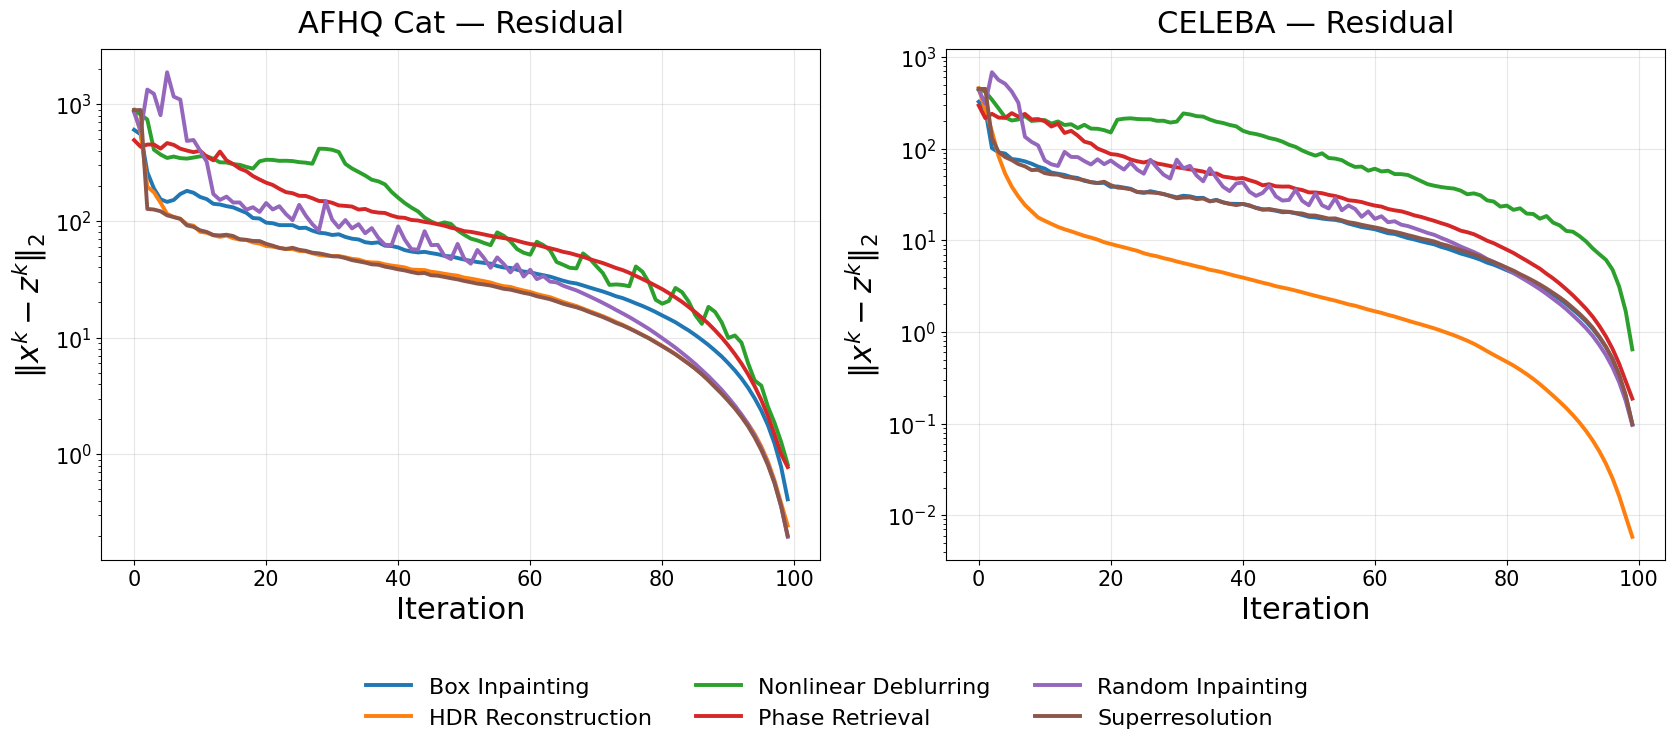

In [9]:
ROOT_DIRS = [
    Path("results_primal_convergence/afhq_cat/ot"),
    Path("results_primal_convergence/celeba/ot"),
    # Path("results_primal_convergence/celebahq/ot"),
]

DATASET_NAMES = [
    "AFHQ Cat",
    "CELEBA",
    # "CelebA-HQ",
]

gu.plot_convergence_two_datasets_shared_legend(
    root_dirs=ROOT_DIRS,
    dataset_names=DATASET_NAMES,
    batch=0,
    save_path=Path("results/convergence_analysis_all_datasets.png"),
    logy=True,
    metrics=["primal_res"],
)

## Time and Memory

In [7]:
root_dir = Path("results_final_difficult/afhq_cat/ot")

df_time_memory = gu.extract_time_memory_summary(root_dir)
gu.save_time_memory_summary(df_time_memory,xlsx_path="time_memory_summary_afhq_cat.xlsx")
display(df_time_memory)
print(root_dir)

,task,method,model,time_average,max_memory_average_gb,experiment_dir
0,hdr_reconstruction,ADMM adaptive,test,20.5017,0.794976,results_final_difficult/afhq_cat/ot/hdr_recons...
1,hdr_reconstruction,ADMM deterministic,test,20.5263,0.793941,results_final_difficult/afhq_cat/ot/hdr_recons...
2,hdr_reconstruction,ADMM stochastic,test,20.4988,0.793531,results_final_difficult/afhq_cat/ot/hdr_recons...
3,hdr_reconstruction,d_flow,test,87.3609,50.383270,results_final_difficult/afhq_cat/ot/hdr_recons...
4,hdr_reconstruction,flow_dps,test,11.9843,0.786169,results_final_difficult/afhq_cat/ot/hdr_recons...
5,hdr_reconstruction,pnp_flow_fbs,test,19.5922,0.772515,results_final_difficult/afhq_cat/ot/hdr_recons...
6,inpainting,ADMM adaptive,test,19.8501,0.793023,results_final_difficult/afhq_cat/ot/inpainting...
7,inpainting,ADMM deterministic,test,19.7203,0.793160,results_final_difficult/afhq_cat/ot/inpainting...
8,inpainting,ADMM stochastic,test,19.8320,0.793336,results_final_difficult/afhq_cat/ot/inpainting...
9,inpainting,d_flow,test,77.4820,50.321671,results_final_difficult/afhq_cat/ot/inpainting...


results_final_difficult/afhq_cat/ot


## PnP-FBS (adaptive vs non-adaptive) vs PnP-ADMM: PSNR vs steps

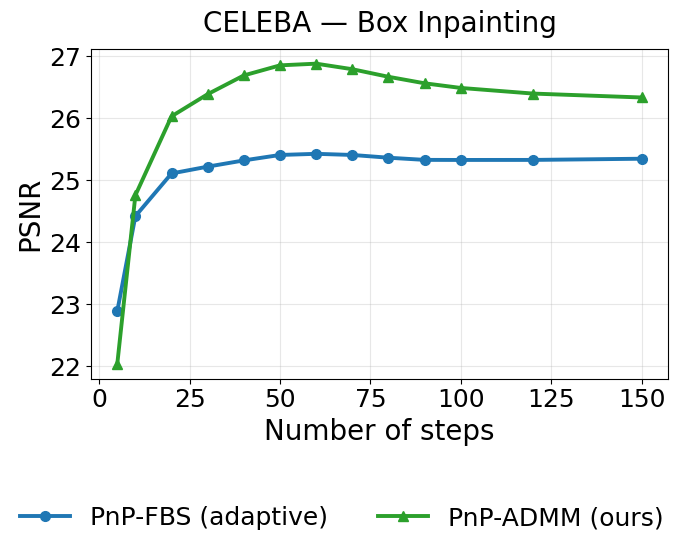

Saved: fbs_vs_admm_psnr_vs_steps.png


In [12]:
BASE_DIR = Path("results_multiple_steps/celeba/ot")
DATASET_NAME = "CELEBA"

TASKS = [
    #"hdr_reconstruction",
    "inpainting",
]

gu.plot_fbs_vs_admm_psnr_vs_steps(
    base_dir=BASE_DIR,
    dataset_name=DATASET_NAME,
    tasks=TASKS,
    metric="psnr",  # or "psnr" / "lpips"
)


## PnP-FBS vs PnP-ADMM: PSNR convergence per iteration (single run)

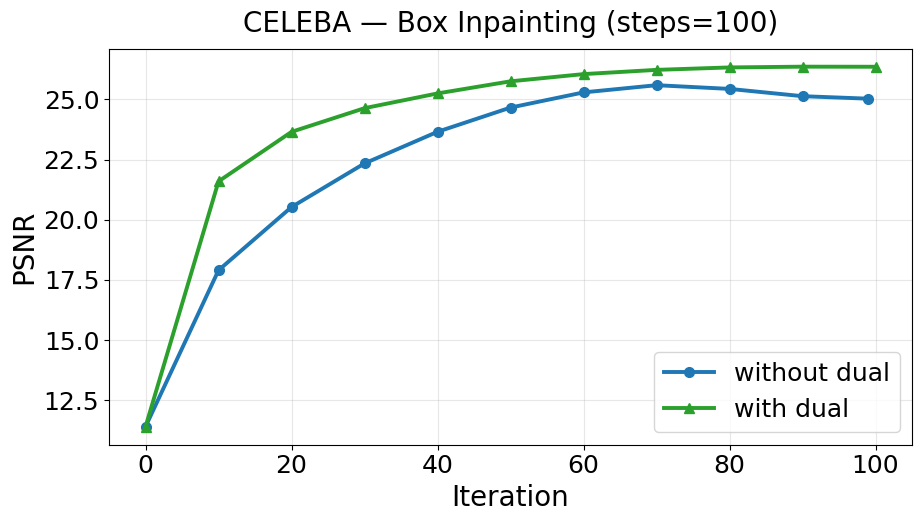

Saved: fbs_vs_admm_psnr_convergence.png


In [9]:
RUNS = [
    {
        "title": "CELEBA — Box Inpainting (steps=100)",
        "fbs_dir": Path(
            "results_dual_analysis/celeba/ot/inpainting/pnp_flow_fbs/test/"
            "steps_pnp=100/lr_pnp=1.0/gamma_style=alpha_1_minus_t/"
            "num_samples=5/alpha=0.5/adaptive_noise=True"
        ),
        "admm_dir": Path(
            "results_dual_analysis/celeba/ot/inpainting/pnp_flow_admm/test/"
            "steps_pnp=100/rho_admm=50/max_cgiter=10/cg_tol=1e-05/"
            "save_norms_admm=False/adaptive_noise=True/deterministic_noise=False/"
            "t_schedule_gamma=1.0/admm_gd_steps=10/beta_rho=2.5/"
            "early_stopping=False/num_denoiser_calls=5"
        ),
    },
]

gu.plot_fbs_vs_admm_psnr_convergence(
    runs=RUNS,
    metric="psnr",
)